# HealthyAir - Data Cleaning Notebook
Run notebooks in order: exploration → cleaning → feature engineering, keeping the raw files unchanged.

## Data cleaning
This notebook creates a cleaned copy, it does not overwrite the raw data but creates df_clean dataset. A fixed seed makes resampling repeatable.

In [28]:
# Import Libraries
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import statsmodels
import scipy
import os
import gcsfs
import warnings
from scipy import stats
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.max_columns", 30)
#pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

print(Path.cwd())
print(PROJECT_ROOT)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("statsmodels:", statsmodels.__version__)

/home/chloekc/datahandling/healthyair/notebooks
/home/chloekc/datahandling/healthyair
Python: 3.12.3
NumPy: 2.5.3
pandas: 3.0.6
SciPy: 1.18.1
Matplotlib: 3.11.1
Seaborn: 0.13.2
statsmodels: 0.15.0


In [26]:
GCS_PROJECT_ID = "healthy_air_analysis"
GCS_BUCKET = "uci_air_quality_20119102"
GCS_FILE = "gs://uci_air_quality_20119102/data_raw/AirQualityUCI.csv"

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FEATURE_DIR = PROJECT_ROOT / "data" / "features"

## 1. Load and validate data

In [2]:
# Load data from Google Cloud Storage
GCS_PROJECT_ID = "healthy_air_analysis"
GCS_BUCKET = "uci_air_quality_20119102"
GCS_FILE = "gs://uci_air_quality_20119102/data_raw/AirQualityUCI.csv"
df = pd.read_csv(GCS_FILE)

# Data contract
required = {"Date", "Time", "CO(GT)", "PT08.S1(CO)", "NMHC(GT)", "C6H6(GT)",
            "PT08.S2(NMHC)", "NOx(GT)", "PT08.S3(NOx)", "NO2(GT)", "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"}
assert required.issubset(df.columns)
#assert set(df["Quality"].unique()).issubset({0, 1, 3})
print("Initial data-contract checks passed.")

print("Dataset:", GCS_BUCKET)
print(f"Rows: {df.shape[0]:,}; columns: {df.shape[1]}")
display(df.head())

Initial data-contract checks passed.
Dataset: uci_air_quality_20119102
Rows: 9,471; columns: 17


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,3/10/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,3/10/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,3/10/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,3/10/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,3/10/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


## 2. Timestamp Analysis

In [3]:
# Preserve original dataset
df_clean = df.copy()

# Combine Date and Time using format "%m/%d/%Y %H:%M:%S" with pd.to_datetime
df_clean["Datetime"] = pd.to_datetime(
    df_clean["Date"].astype("string").str.strip() + " " +
    df_clean["Time"].astype("string").str.strip(),
    format="%m/%d/%Y %H:%M:%S",
    errors="coerce"
)

# Check
print("Total rows:", len(df_clean))
print("Valid timestamps:", df_clean["Datetime"].notna().sum())
print("Missing timestamps:", df_clean["Datetime"].isna().sum())

print("\nFirst timestamp:", df_clean["Datetime"].min())
print("Last timestamp:", df_clean["Datetime"].max())

Total rows: 9471
Valid timestamps: 9357
Missing timestamps: 114

First timestamp: 2004-03-10 18:00:00
Last timestamp: 2005-04-04 14:00:00


In [4]:
# Non empty rows with missing timestamp values
missing_dates = df_clean[df_clean["Datetime"].isna()]

print("Rows with missing timestamps:", len(missing_dates))

display(missing_dates.head(10))

print("\nNon-empty values in missing timestamp rows:")
print(missing_dates.notna().sum())

Rows with missing timestamps: 114


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16,Datetime
9357,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9358,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9359,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9360,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9361,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9362,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9363,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9364,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9365,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
9366,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT



Non-empty values in missing timestamp rows:
Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
NMHC(GT)         0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
Unnamed: 15      0
Unnamed: 16      0
Datetime         0
dtype: int64


In [5]:
# Remove rows without a valid timestamp as rows have no data
df_clean = df_clean.dropna(subset=["Datetime"]).copy()

# Sort chronologically
df_clean = df_clean.sort_values("Datetime").reset_index(drop=True)

print("Cleaned dataset shape:", df_clean.shape)
print("First observation:", df_clean["Datetime"].min())
print("Last observation:", df_clean["Datetime"].max())

# Calculate time differences between observations
df_clean["Time_Difference"] = df_clean["Datetime"].diff()

# Check the intervals
print(df_clean["Time_Difference"].value_counts().head(10))

# Identify gaps larger than one hour
gaps = df_clean[df_clean["Time_Difference"] > pd.Timedelta(hours=1)]

print("\nGaps larger than one hour:", len(gaps))

Cleaned dataset shape: (9357, 18)
First observation: 2004-03-10 18:00:00
Last observation: 2005-04-04 14:00:00
Time_Difference
0 days 01:00:00    9356
Name: count, dtype: int64

Gaps larger than one hour: 0


## 3. Check duplicates, gaps and ranges
Timestamp Analysis Result: every observation is exactly one hour apart, target for next hour prediction is viable.

In [6]:
print("Date range:")
print(df_clean["Datetime"].min(), "to", df_clean["Datetime"].max())
display(df_clean[["Datetime", "Date", "Time"]].head(10))
display(df_clean[["Datetime", "Date", "Time"]].tail(5))

Date range:
2004-03-10 18:00:00 to 2005-04-04 14:00:00


,Datetime,Date,Time
0,2004-03-10 18:00:00,3/10/2004,18:00:00
1,2004-03-10 19:00:00,3/10/2004,19:00:00
2,2004-03-10 20:00:00,3/10/2004,20:00:00
3,2004-03-10 21:00:00,3/10/2004,21:00:00
4,2004-03-10 22:00:00,3/10/2004,22:00:00
5,2004-03-10 23:00:00,3/10/2004,23:00:00
6,2004-03-11 00:00:00,3/11/2004,0:00:00
7,2004-03-11 01:00:00,3/11/2004,1:00:00
8,2004-03-11 02:00:00,3/11/2004,2:00:00
9,2004-03-11 03:00:00,3/11/2004,3:00:00


,Datetime,Date,Time
9352,2005-04-04 10:00:00,4/4/2005,10:00:00
9353,2005-04-04 11:00:00,4/4/2005,11:00:00
9354,2005-04-04 12:00:00,4/4/2005,12:00:00
9355,2005-04-04 13:00:00,4/4/2005,13:00:00
9356,2005-04-04 14:00:00,4/4/2005,14:00:00


In [7]:
print(df_clean[["Unnamed: 15", "Unnamed: 16"]].notna().sum())

Unnamed: 15    0
Unnamed: 16    0
dtype: int64


In [8]:
df_clean = df_clean.drop(columns=["Unnamed: 15", "Unnamed: 16"])

## 4. Missing-value strategy

This template retains missing measurements rather than imputing across the full time series. Avoid interpolation that uses future observations when forecasting.

In [9]:
df_clean = df_clean.drop(columns=["Time_Difference"])

In [10]:
df_clean = df_clean.dropna(
    subset=["Datetime"]
)

In [11]:
df_clean = df_clean.replace(
    -200,
    np.nan
)

In [12]:
missing_pct = (
    df_clean.isnull()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

print(missing_pct)

NMHC(GT)         90.231912
CO(GT)           17.986534
NO2(GT)          17.548360
NOx(GT)          17.516298
C6H6(GT)          3.911510
PT08.S2(NMHC)     3.911510
PT08.S3(NOx)      3.911510
PT08.S1(CO)       3.911510
T                 3.911510
RH                3.911510
PT08.S4(NO2)      3.911510
PT08.S5(O3)       3.911510
AH                3.911510
Date              0.000000
Time              0.000000
Datetime          0.000000
dtype: float64


In [13]:
# Impute missing values with median
numeric_cols = df_clean.select_dtypes(
    include="number"
).columns

for col in numeric_cols:

    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

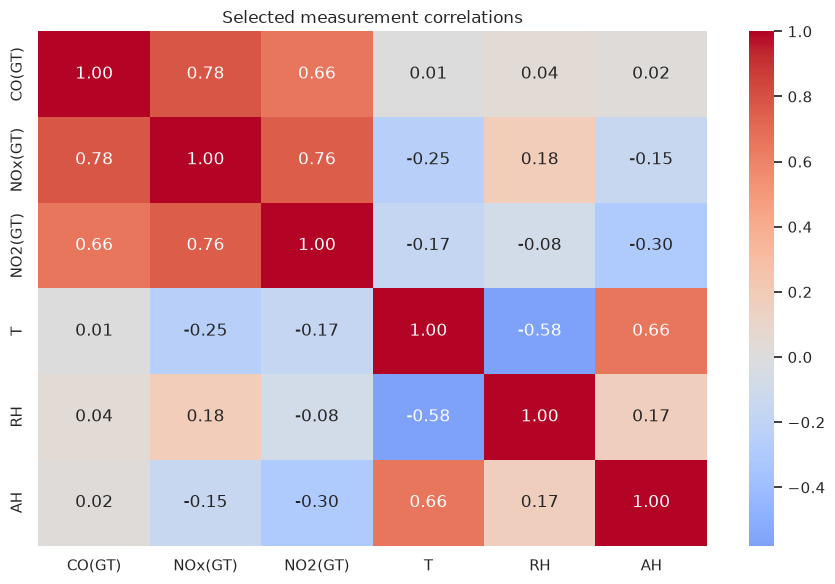

In [14]:
# Relationships
selected = [c for c in ["CO(GT)", "NOx(GT)", "NO2(GT)", "T", "RH", "AH"] if c in df_clean.columns]
if len(selected) > 1:
    plt.figure(figsize=(9, 6))
    sns.heatmap(df_clean[selected].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
    plt.title("Selected measurement correlations")
    plt.tight_layout()
    plt.show()

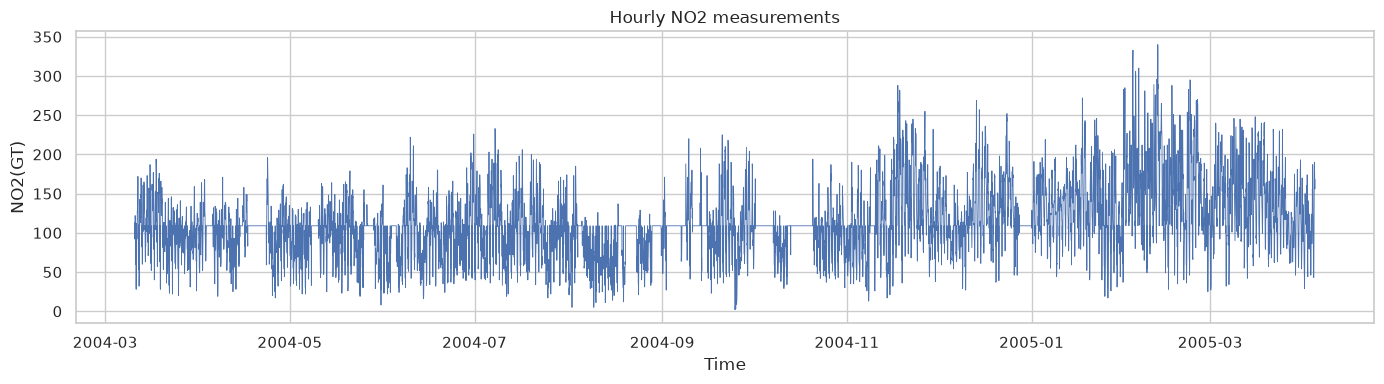

In [15]:
if "Datetime" in df_clean and "NO2(GT)" in df_clean:
    p = df_clean[["Datetime", "NO2(GT)"]].dropna().sort_values("Datetime")
    plt.figure(figsize=(14, 4))
    plt.plot(p.Datetime, p["NO2(GT)"], linewidth=.6)
    plt.xlabel("Time"); plt.ylabel("NO2(GT)")
    plt.title("Hourly NO2 measurements")
    plt.tight_layout(); plt.show()

In [16]:
print("Duplicate timestamps:", df_clean["Datetime"].duplicated().sum())

Duplicate timestamps: 0


In [17]:
print("Final rows:", len(df_clean))
print("Final columns:", len(df_clean.columns))

Final rows: 9357
Final columns: 16


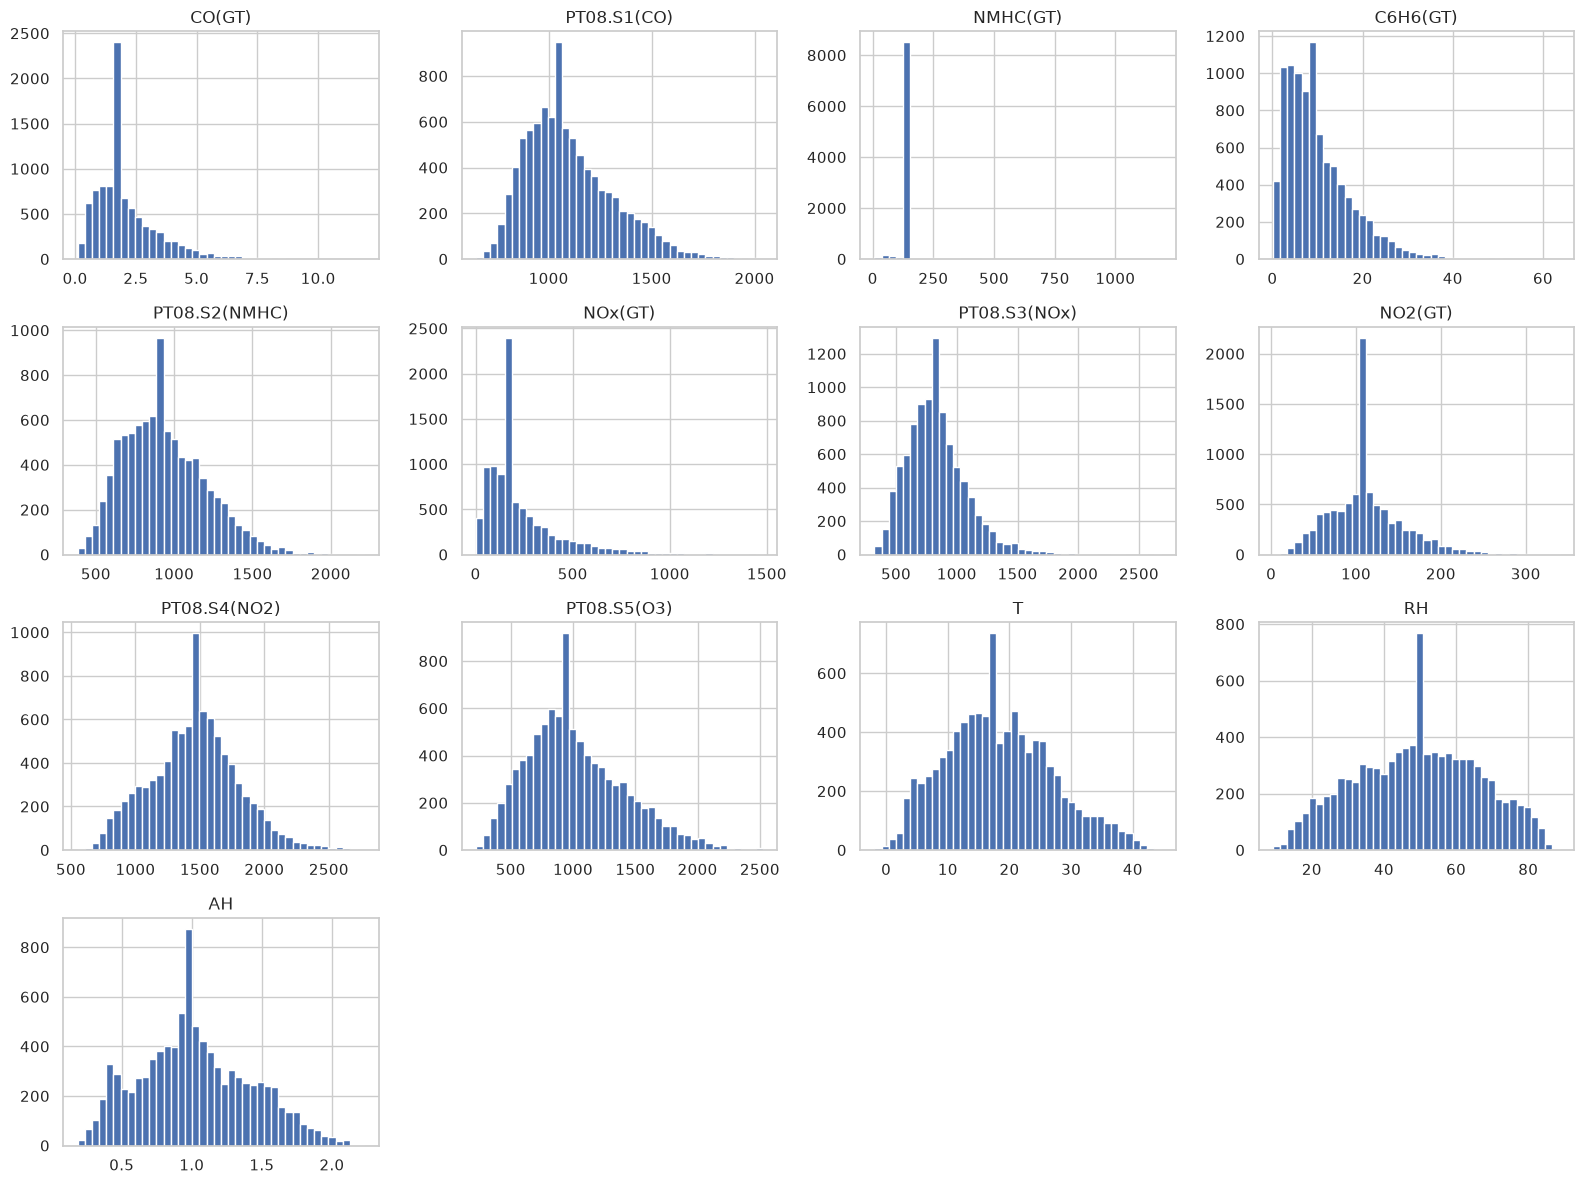

In [18]:
# Measurement Distributions
numeric = df_clean.select_dtypes(include="number")
numeric.hist(figsize=(16, 12), bins=40)
plt.tight_layout()
plt.show()

In [19]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           9357 non-null   str           
 1   Time           9357 non-null   str           
 2   CO(GT)         9357 non-null   float64       
 3   PT08.S1(CO)    9357 non-null   float64       
 4   NMHC(GT)       9357 non-null   float64       
 5   C6H6(GT)       9357 non-null   float64       
 6   PT08.S2(NMHC)  9357 non-null   float64       
 7   NOx(GT)        9357 non-null   float64       
 8   PT08.S3(NOx)   9357 non-null   float64       
 9   NO2(GT)        9357 non-null   float64       
 10  PT08.S4(NO2)   9357 non-null   float64       
 11  PT08.S5(O3)    9357 non-null   float64       
 12  T              9357 non-null   float64       
 13  RH             9357 non-null   float64       
 14  AH             9357 non-null   float64       
 15  Datetime       9357 non-null   d

In [20]:
df_clean.describe()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Datetime
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357
mean,2.089302,1098.392433,156.721599,10.009447,937.973923,235.178903,834.339959,112.373303,1456.528054,1020.562894,18.297574,49.248509,1.024352,2004-09-21 16:00:00
min,0.100000,647.000000,7.000000,0.100000,383.000000,2.000000,322.000000,2.000000,551.000000,221.000000,-1.900000,9.200000,0.184700,2004-03-10 18:00:00
25%,1.200000,941.000000,150.000000,4.600000,743.000000,112.000000,666.000000,86.000000,1242.000000,742.000000,12.000000,36.600000,0.746100,2004-06-16 05:00:00
50%,1.800000,1063.000000,150.000000,8.200000,909.000000,180.000000,806.000000,109.000000,1463.000000,963.000000,17.800000,49.600000,0.995400,2004-09-21 16:00:00
75%,2.600000,1221.000000,150.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200,2004-12-28 03:00:00
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000,2005-04-04 14:00:00
std,1.323024,212.911465,67.058156,7.311771,261.625561,195.091025,251.808888,43.948519,339.370072,390.784960,8.658221,16.974949,0.395878,NaN


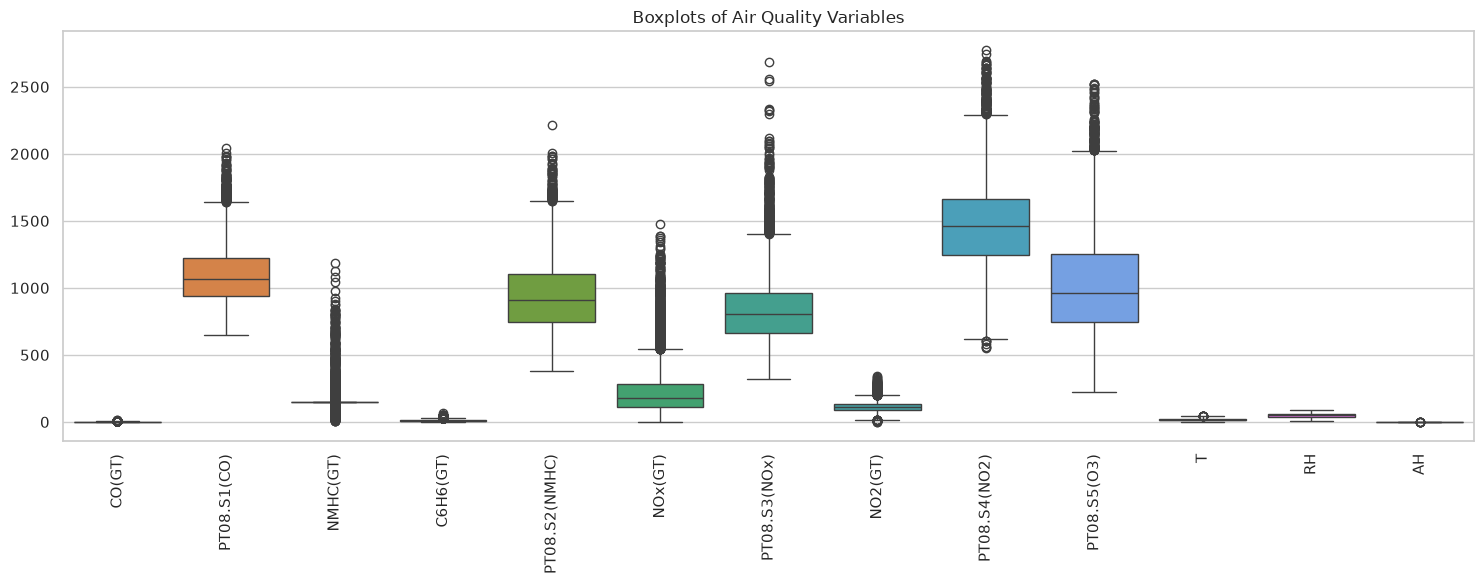

In [21]:
numeric_cols = (
    df_clean.select_dtypes(
        include="number"
    ).columns
)

plt.figure(figsize=(15, 6))

sns.boxplot(
    data=df_clean[numeric_cols]
)

plt.xticks(
    rotation=90
)

plt.title(
    "Boxplots of Air Quality Variables"
)

plt.tight_layout()

plt.show()

In [22]:
outlier_summary = []

for col in numeric_cols:

    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    outlier_summary.append(
        [col, count]
    )

outliers_df = pd.DataFrame(
    outlier_summary,
    columns=[
        "Feature",
        "Outlier_Count"
    ]
)

outliers_df.sort_values(
    "Outlier_Count",
    ascending=False
)


,Feature,Outlier_Count
0,CO(GT),1898
7,NO2(GT),1696
2,NMHC(GT),914
3,C6H6(GT),606
6,PT08.S3(NOx),602
5,NOx(GT),509
1,PT08.S1(CO),484
9,PT08.S5(O3),458
8,PT08.S4(NO2),450
4,PT08.S2(NMHC),426


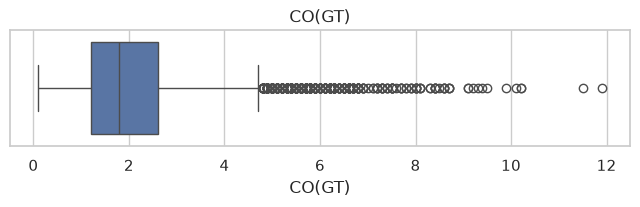

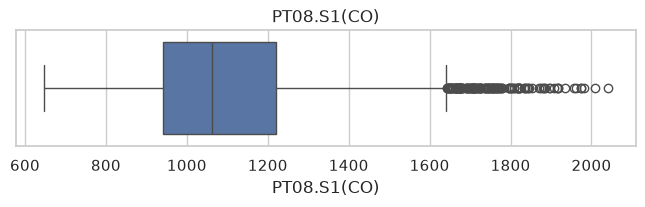

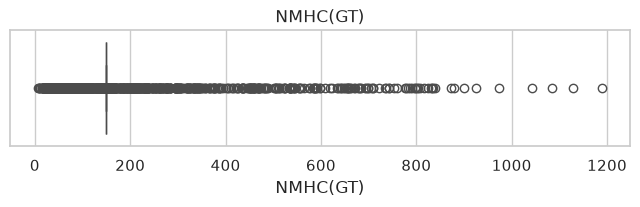

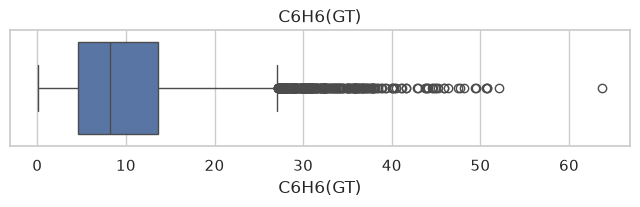

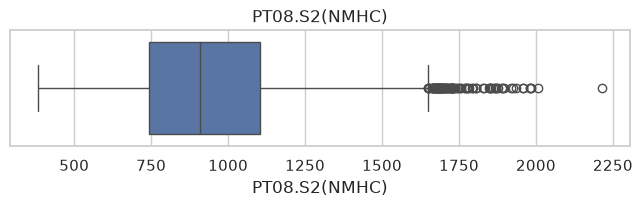

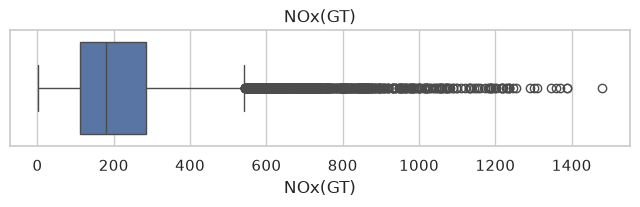

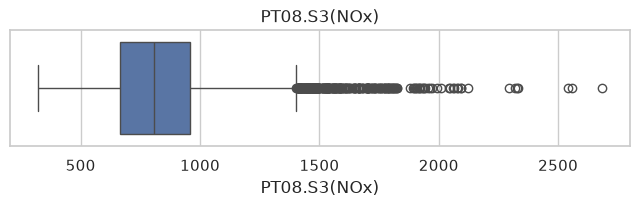

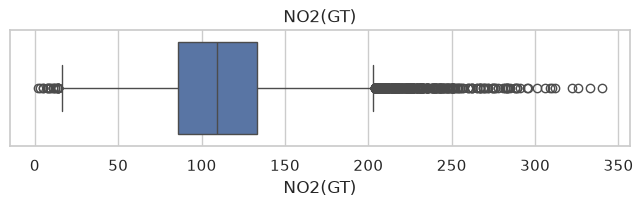

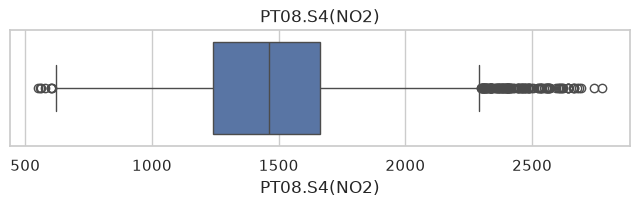

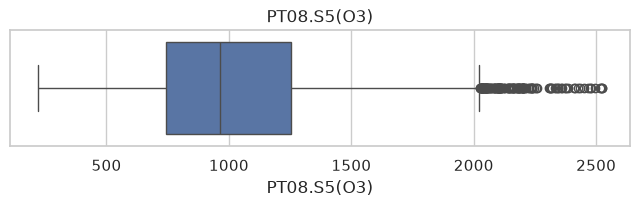

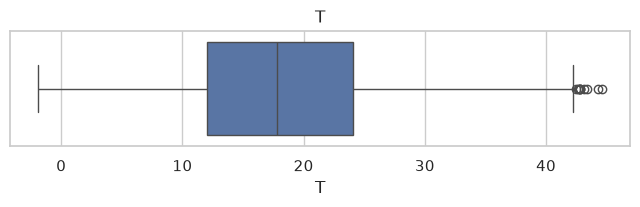

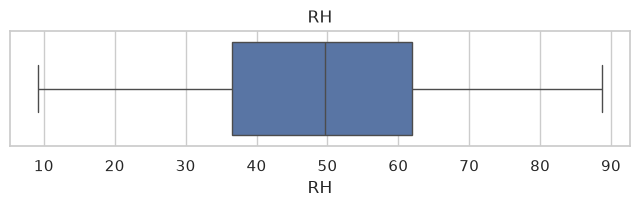

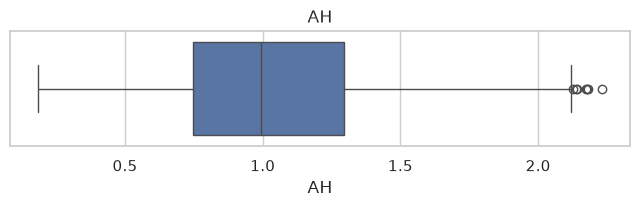

In [23]:
# Outliers
numeric_cols = df_clean.select_dtypes(include="number").columns
for col in numeric_cols:

    plt.figure(figsize=(8, 1.5))

    sns.boxplot(
        x=df_clean[col]
    )

    plt.title(col)
    plt.show()

## 5. Save processed data

In [24]:
cleaned = df_clean.copy()
print("Raw rows:", len(df))
print("Cleaned rows:", len(cleaned))
print("Remaining missing measurement cells:", int(cleaned[numeric_cols].isna().sum().sum()))

Raw rows: 9471
Cleaned rows: 9357
Remaining missing measurement cells: 0


In [29]:
processed_dir = PROJECT_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
parquet_path = processed_dir / "air_quality_cleaned.parquet"
csv_path = processed_dir / "air_quality_cleaned.csv"
cleaned.to_parquet(parquet_path, index=False)
cleaned.to_csv(csv_path, index=False)
print("Saved:", parquet_path)

Saved: /home/chloekc/datahandling/healthyair/data/processed/air_quality_cleaned.parquet


## 6. Document analysis and decisions
Missing value analysis
Duplicate analysis
Correlation heatmap
One combined boxplot figure
Outlier count table

Two unnamed columns contained 100% missing values and were removed. All remaining variables contained approximately 1.2% missing values (114 observations), which were imputed using the median value of each numerical feature. Because the proportion of missing data was low, all environmental and sensor variables were retained for subsequent modelling
`-200` missing-value conversion/deletion, timestamp parsing, duplicate/gap findings, rows removed and imputation was deferred. Prevent information from validation/test periods leaking into training.

1. Drop completely empty columns
2. Keep rows with valid timestamps
3. Impute numerical features with median:

For air-quality data, median imputation is a good baseline: Robust to pollution spikes and less affected by outliers than mean.
Although, for time series data, impute using forward-fill and backward-fill methods due to the temporal nature of the dataset.